
**Curso: modelos de aprendizaje**

**UNIDAD 2**


---

*   NOMBRE: Rodriguez Montoya Diego
*   NO CONTROL: 22111400



In [40]:
import pandas as pd
data_df = pd.read_csv('data.csv')

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Librerías para preprocesamiento e ing de características
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder,StandardScaler, OrdinalEncoder,FunctionTransformer

# Librerías para la canalización
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import make_pipeline

# Librerías para la regresión
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, mean_squared_error, r2_score, confusion_matrix, precision_score,recall_score,accuracy_score
from sklearn.decomposition import PCA

from sklearn.preprocessing import PolynomialFeatures

---

## **<font color=" #895cf9">Explica brevemente el uso de las librerias del segmento de codigo anterior, haciendo uso de la siguiente tabla</font>**


| Library | Explanation  |
|----------|--------------|
|**import numpy as np**| Datacxcxcxvxv manipulation through mathematical operations and preprocessing.	|
|**import**|asassasa	|
|**mport numpy as np**| ffefefe |
|**importsdsd** | dsdsd |
|**import** |  gfdgf|
|**import** |  |
|**import** | |
|**import** | .|
|**import**|  |
|**import** | |
|**import**| |
|**import**|  |
|**import**| |
|**import**|  |







---

In [42]:
#lectura del .csv con pandas


# **Parte 1**. EDA

Haz que el `id` sea el índice del dataframe y efectúa una exploración inicial de los datos a través de:

In [43]:
#utilice funcion .set_index()
#Guarde los cambios con inplace=True
#Escriba su codigo
data_df.set_index('id', inplace=True)


In [44]:
data_df

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
id,,,,,,,,,,,,,,,,,,,,,
842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820




1a) Estadísticas descriptivas para todas las variables del dataframe.

In [45]:
#.describe para variables Numericas
data_df.describe()

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [46]:
#.describe() para variable categoricas
data_df.describe(include='object')

,diagnosis
count,569
unique,2
top,B
freq,357


1b) Valores únicos por variable para identificar posibles variables categóricas.

In [47]:
# Se hace una lista de variables numéricas y otra de categóricas.

#-----------------------------------------------------
num_cols = data_df.select_dtypes(include=np.number).columns.tolist() #para variables numericas
cat_cols = data_df.select_dtypes(exclude=np.number).columns.tolist() #para variables Categoricas
#-----------------------------------------------------
print('Numericas:', len(num_cols))
print('Categoricas:', len(cat_cols))

Numericas: 30
Categoricas: 1


In [48]:
for col in cat_cols:
  print(data_df[col].value_counts())   # B = benigno, M = maligno


diagnosis
B    357
M    212
Name: count, dtype: int64


In [49]:
data_df.nunique()

,0
diagnosis,2
radius_mean,456
texture_mean,479
perimeter_mean,522
area_mean,539
smoothness_mean,474
compactness_mean,537
concavity_mean,537
concave points_mean,542
symmetry_mean,432


1c) Búsqueda de valores faltantes.

In [50]:
#Explica cada linea de codigo
print('Número valores faltantes: ')# imprime el encabezado
for col in data_df.columns: #hace un recorrido por cada una de las columna
  valor=sum(data_df[col].isna()) #isna() marca True las celdas vacias y el sum() cuenta los Trues
  porcentaje=data_df[col].isna().mean()*100 #mean () de booleanos = proporcion de faltantes *100
  print('{}:{}: porcentaje :{}'.format(col,valor,porcentaje)) #muetsra columna n de faltantes y porcentaje

Número valores faltantes: 
diagnosis:0: porcentaje :0.0
radius_mean:0: porcentaje :0.0
texture_mean:0: porcentaje :0.0
perimeter_mean:0: porcentaje :0.0
area_mean:0: porcentaje :0.0
smoothness_mean:0: porcentaje :0.0
compactness_mean:0: porcentaje :0.0
concavity_mean:0: porcentaje :0.0
concave points_mean:0: porcentaje :0.0
symmetry_mean:0: porcentaje :0.0
fractal_dimension_mean:0: porcentaje :0.0
radius_se:0: porcentaje :0.0
texture_se:0: porcentaje :0.0
perimeter_se:0: porcentaje :0.0
area_se:0: porcentaje :0.0
smoothness_se:0: porcentaje :0.0
compactness_se:0: porcentaje :0.0
concavity_se:0: porcentaje :0.0
concave points_se:0: porcentaje :0.0
symmetry_se:0: porcentaje :0.0
fractal_dimension_se:0: porcentaje :0.0
radius_worst:0: porcentaje :0.0
texture_worst:0: porcentaje :0.0
perimeter_worst:0: porcentaje :0.0
area_worst:0: porcentaje :0.0
smoothness_worst:0: porcentaje :0.0
compactness_worst:0: porcentaje :0.0
concavity_worst:0: porcentaje :0.0
concave points_worst:0: porcentaje :

1d) Diagrama de barras para determinar la frecuencia de los diagnósticos (cantidad de observaciones con resultado benigno y maligno)

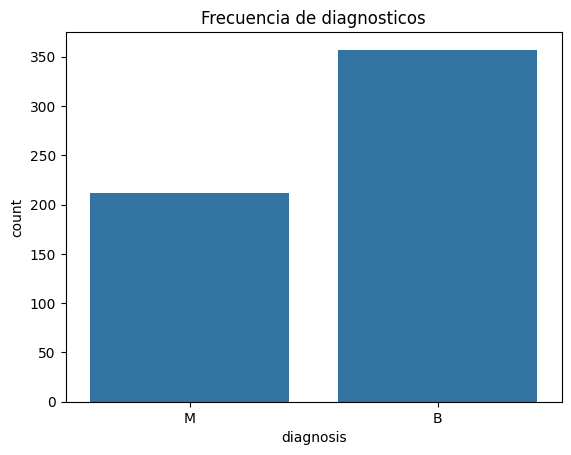

In [51]:
#utilice sns.countplot()
sns.countplot(data=data_df, x='diagnosis')
plt.title('Frecuencia de diagnosticos')
plt.show()

2. Como hay tres valores relacionados con la misma característica (`mean`, `se` y `worst`) es muy probable que exista multicolinealidad en el conjunto.

La multicolinealidad en regresión es una condición que ocurre cuando algunas variables predictoras están fuertemente correlacionadas entre sí, de tal manera que si se incluyen simultáneamente en un modelo, impiden explicar de manera correcta el efecto que cada una tiene sobre la variable respuesta. Existen muchas formas de analizar si hay colinealidad en los modelos, una de ellas es el alto coeficiente de correlación entre variables.

Para observar este efecto, elabora un mapa de calor que cuantifique la correlación de las variables numéricas en el dataframe.

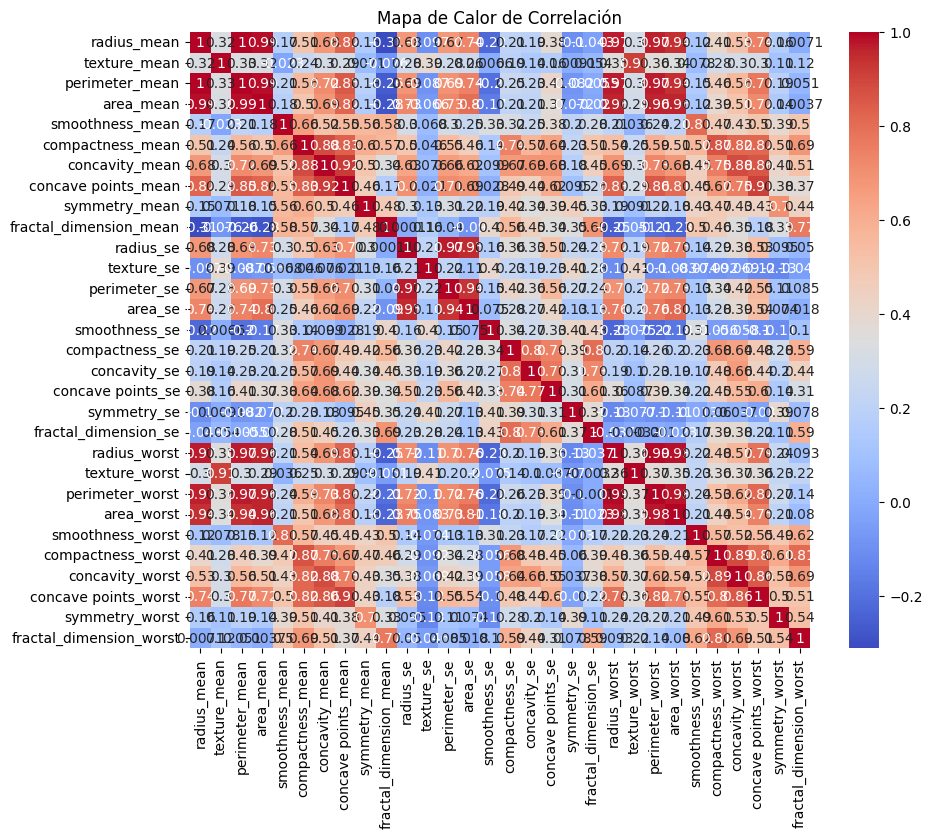

In [52]:
numeric_df = data_df.select_dtypes(include=[float, int])

plt.figure(figsize=(10, 8))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm')
plt.title('Mapa de Calor de Correlación')
plt.show()

Si te fijas en los valores de correlación entre las variables `_mean` y `_worst` es evidente la multicolinearidad.

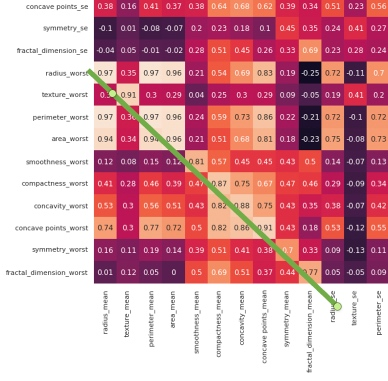

Por ejemplo, la columna `radius_mean` tiene una correlación de 0.97 con la columna `radius_worst`. Esto es algo inevitable, porque las columnas "peores" son esencialmente solo un subconjunto de las columnas "medias".

Para solucionar el problema numérico de la multicolinealidad, tradicionalmente se recurre a eliminar variables o efectuar análisis de componentes principales (PCA) con las `X`’s y usar los componentes como variables independientes en un modelo final.

Conduciremos esta actividad en esos dos sentidos.


# **Parte 2**. Modelo con eliminación de variables altamente correlacionadas  

Elimina las variables altamente correlacionadas:

3a) Ahora que sabes que las variables `_mean` y `_worst` tienen correlación alta, hay que quitar del dataframe un conjunto. Borra las columnas `_worst`.

In [53]:
#Elimine TODAS las columnas _worst

columnas_worst = [c for c in data_df.columns if c.endswith('_worst')]

#para borrar las columnas _worst

new_data_df = data_df.drop(columns=columnas_worst)
#Convierte new_data_df en Dataframe usando .DataFrame() de la libreria de pandas

new_data_df = pd.DataFrame(new_data_df)

En las graficas de dispersion, los patrones lineales en los diagramas de dispersion se refieren a la relacion entre dos variables que sigue una tendencia aproximadamente en linea recta, ya sea en direccion ascendente o descentende

* **Patron lineal positivo**: Si la linea se inclina hacia arriba (de izquierda a derecha), indica que hay una relacion directa entre las variables: cuando la variable aumenta, la otra tambien lo hace, es decir, CORRELACION POSITIVA

* **Patron lineal negativo**: si la linea se incluna hacia abajo (de izquierda a derecha), indica quue cuando una variable aumenta, la otra disminuye, es decir, CORRELACION NEGATIVA

* **Patron lineal perfecto**, si los puntos siguen una linea recta perfecta, la relacion entre las variables es exactamente lineal, sin desviaciones.


3b. Entre las variables `_mean`, identifica patrones lineales con diagramas de dispersión usando:

    sns.pairplot(data=nuevo_df[['radius_mean',
        'texture_mean',
        'perimeter_mean',
        'area_mean',
        'smoothness_mean',
        'compactness_mean',
        'concavity_mean',
        'concave points_mean',
        'symmetry_mean',
        'fractal_dimension_mean']])



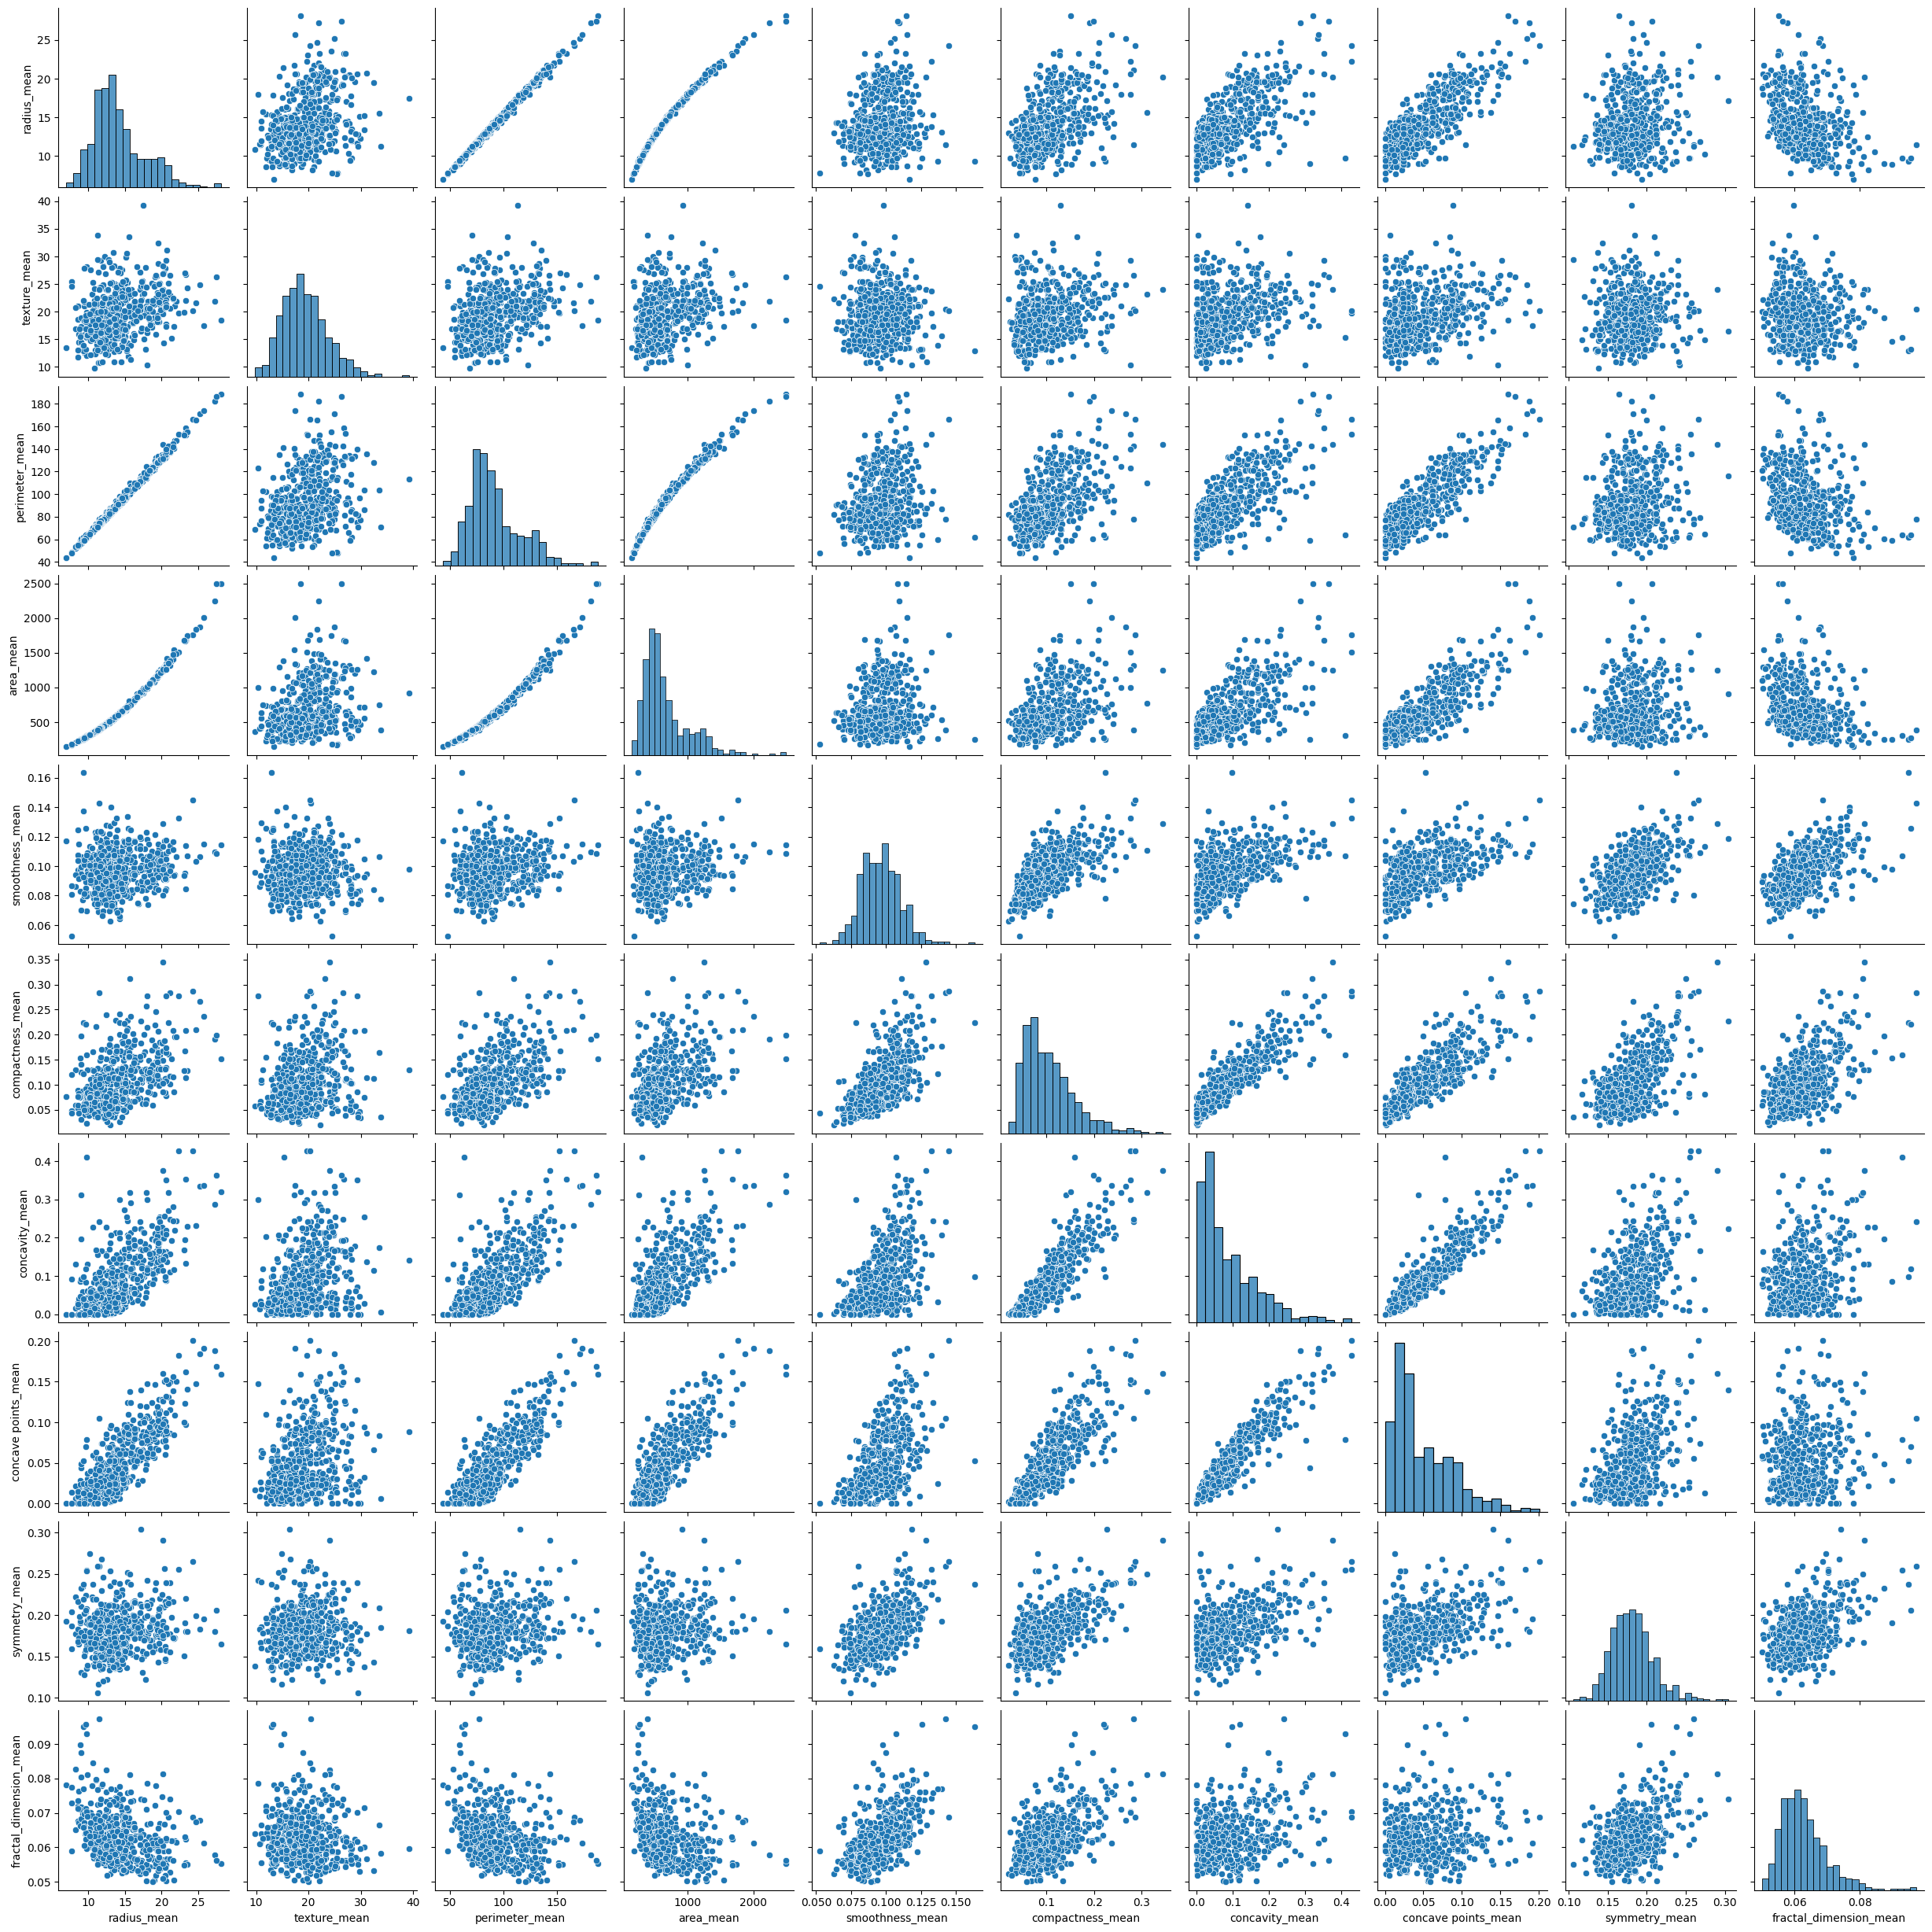

In [54]:
#Pega aqui el codigo sns.pairplot()

sns.pairplot(data=new_data_df[['radius_mean', 'texture_mean','perimeter_mean','area_mean',
        'smoothness_mean','compactness_mean','concavity_mean','concave points_mean',
        'symmetry_mean','fractal_dimension_mean']])
plt.show()

De la matriz podrás observar relaciones lineales bastante evidentes entre:


*   `radius_mean`, `perimeter_mean` y `area_mean`
*   `compactness_mean`, `concavity_mean`, `concave_points_mean`

Sabemos que el perímetro y el área de un círculo, se calculan a partir del radio. Entonces, la relación entre las primeras tres variables es muy clara para nosotros.

3c) Elabora otro mapa de calor confirmar con los valores de correlación.


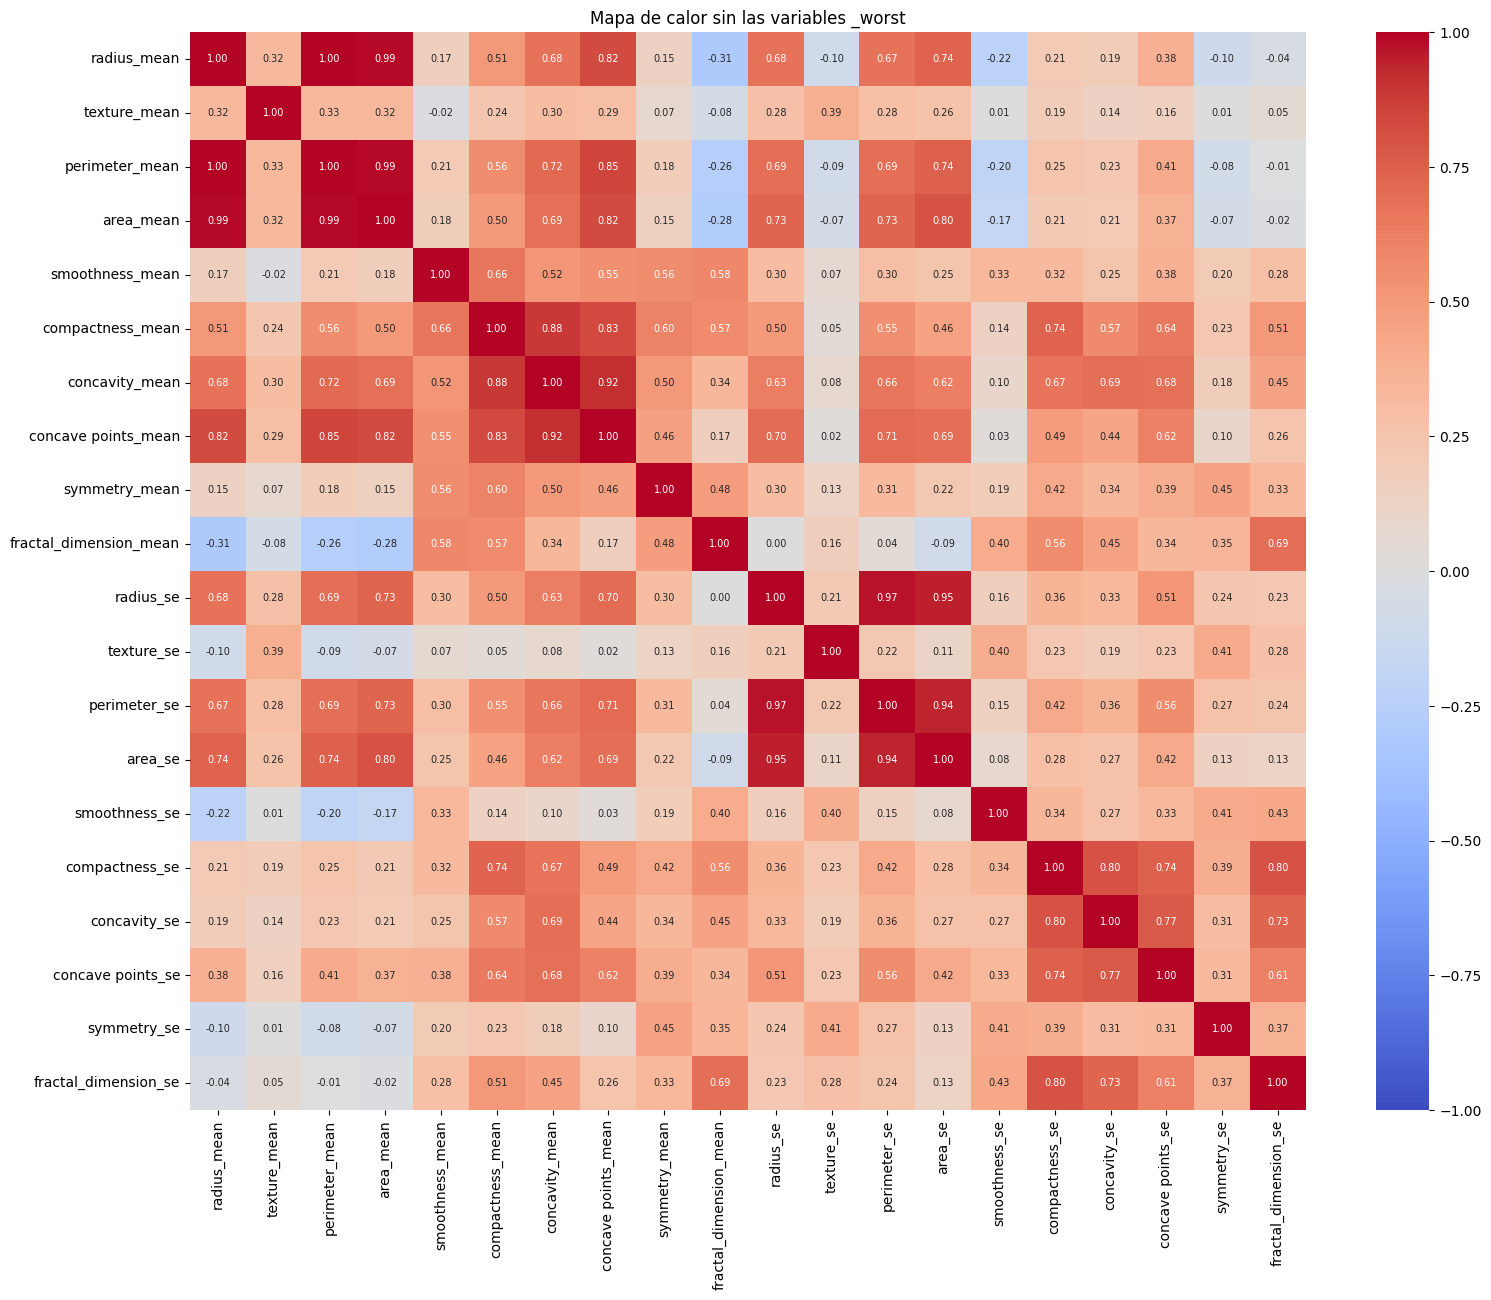

In [55]:
#Agrega codigo para el mapa de calor

plt.figure(figsize=(18, 14))
sns.heatmap(new_data_df.select_dtypes(include=np.number).corr(), annot=True, fmt='.2f', annot_kws={'size': 7}, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Mapa de calor sin las variables _worst')
plt.show()

3d) Después de observar los valores, nos quedaremos con sólo una variable de cada trío: `radius_mean` y `compactness_mean`. Elimina las restantes, no sólo del conjunto `_mean`, sino también de `_se`.

In [56]:
#escriba TODAS las columnas que seran eliminadas
columnas_a_eliminar=['perimeter_mean','area_mean','concavity_mean','concave points_mean',
                     'perimeter_se','area_se','concavity_se','concave points_se']

#Convierte new_data_df en Dataframe usando .DataFrame() de la libreria de pandas
new_data_df=pd.DataFrame(new_data_df.drop(columns=columnas_a_eliminar))
new_data_df



,diagnosis,radius_mean,texture_mean,smoothness_mean,compactness_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,smoothness_se,compactness_se,symmetry_se,fractal_dimension_se
id,,,,,,,,,,,,,
842302,M,17.99,10.38,0.11840,0.27760,0.2419,0.07871,1.0950,0.9053,0.006399,0.04904,0.03003,0.006193
842517,M,20.57,17.77,0.08474,0.07864,0.1812,0.05667,0.5435,0.7339,0.005225,0.01308,0.01389,0.003532
84300903,M,19.69,21.25,0.10960,0.15990,0.2069,0.05999,0.7456,0.7869,0.006150,0.04006,0.02250,0.004571
84348301,M,11.42,20.38,0.14250,0.28390,0.2597,0.09744,0.4956,1.1560,0.009110,0.07458,0.05963,0.009208
84358402,M,20.29,14.34,0.10030,0.13280,0.1809,0.05883,0.7572,0.7813,0.011490,0.02461,0.01756,0.005115
...,...,...,...,...,...,...,...,...,...,...,...,...,...
926424,M,21.56,22.39,0.11100,0.11590,0.1726,0.05623,1.1760,1.2560,0.010300,0.02891,0.01114,0.004239
926682,M,20.13,28.25,0.09780,0.10340,0.1752,0.05533,0.7655,2.4630,0.005769,0.02423,0.01898,0.002498
926954,M,16.60,28.08,0.08455,0.10230,0.1590,0.05648,0.4564,1.0750,0.005903,0.03731,0.01318,0.003892


Observa la distribución de las variables resultantes (deben ser 12, sin contar la columna de indice):

4a) Utilizando histogramas. Guarda en una variable (`skew_cols`) las que tengan marcado sesgo positivo. Para dar seguridad a tu selección, elige aquellas cuyo resultado de aplicar la función `skew()` sea mayor a 1.

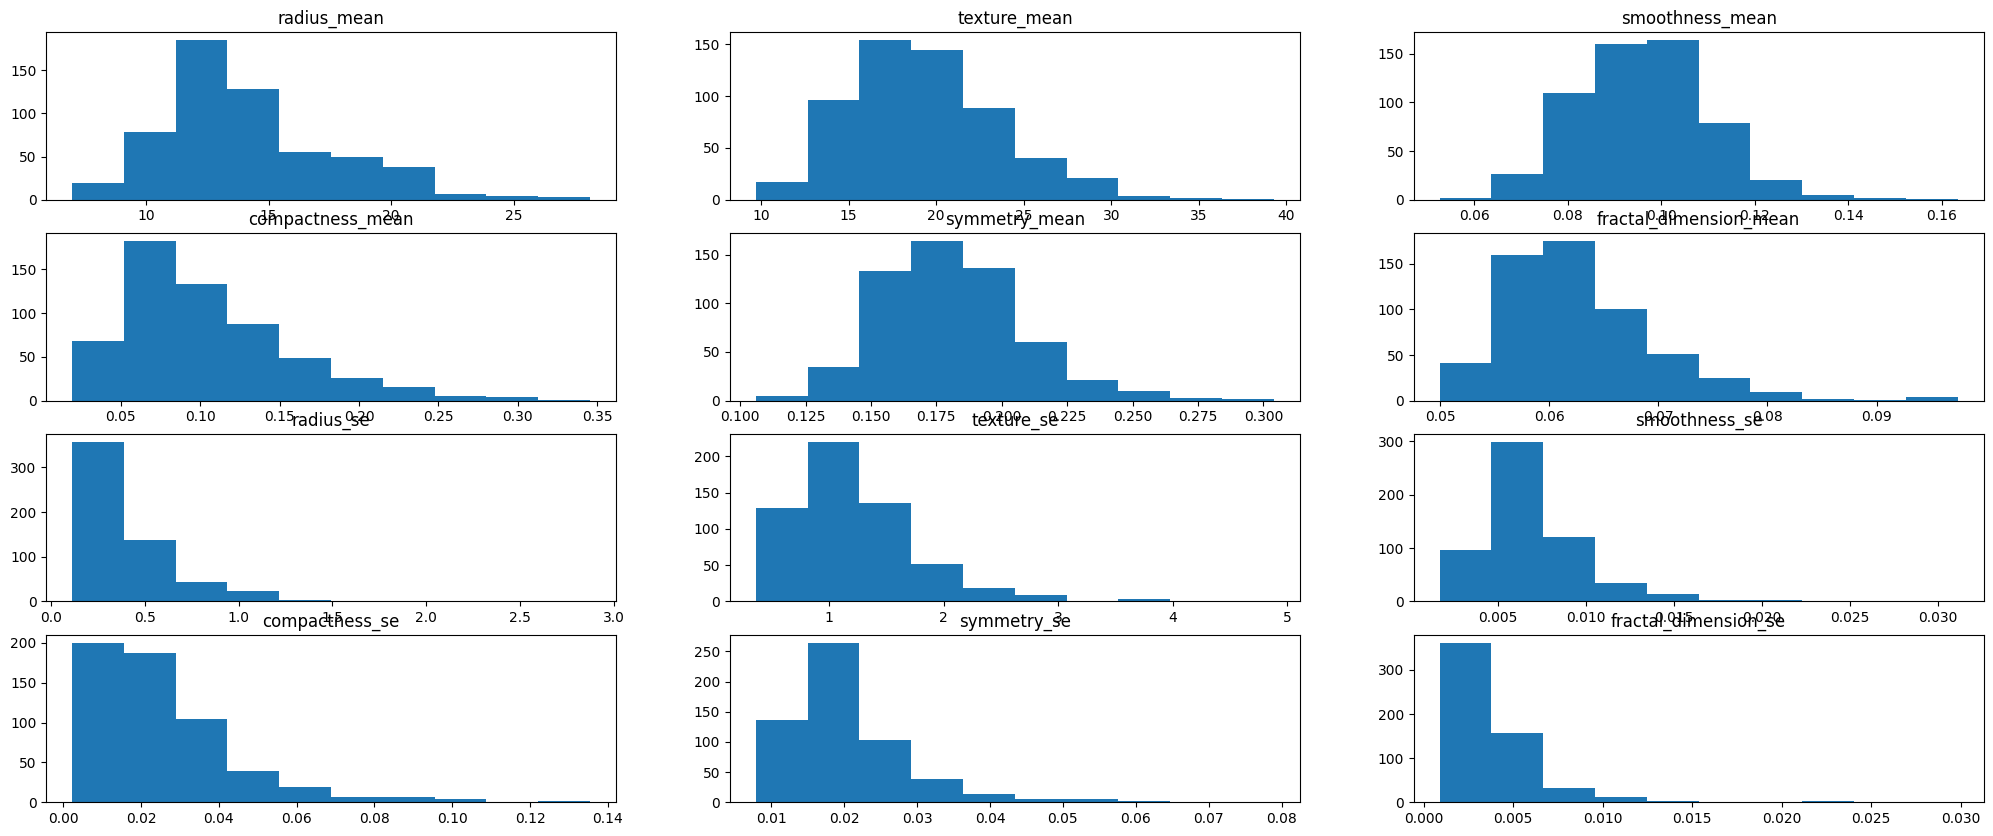

In [57]:
#EXPLICA CADA LINEA DE CODIGO
skew_cols_df=pd.DataFrame()
fig, axes =plt.subplots(4,3, figsize=(25,10)) #25 es el ancho, 10 altura   ---- 4,3 significa que seran  4 filas y 3 columnas
axes = axes.ravel()#convierte la matriz de ejes en una lista de 12 para recorrerla fácil
num_cols = new_data_df.select_dtypes(include=np.number).columns.tolist()#12 variables numéricas


for col, ax in zip (num_cols, axes):#empareja cada variable con su gráfica
  ax.hist(new_data_df[col])#dibuja histograma
  ax.set(title = f'{col}', xlabel=None)
  if new_data_df[col].skew()>1 : skew_cols_df[col] =new_data_df[col]#skew() mide asimetría; si es > 1, la guarda

skew_cols = skew_cols_df.columns.values#variables sesgadas



4b) Dibujando box plots de todas las variables. Guarda en una variable (`scale_cols`) aquellas que no se encuentren en el intervalo [0,1]


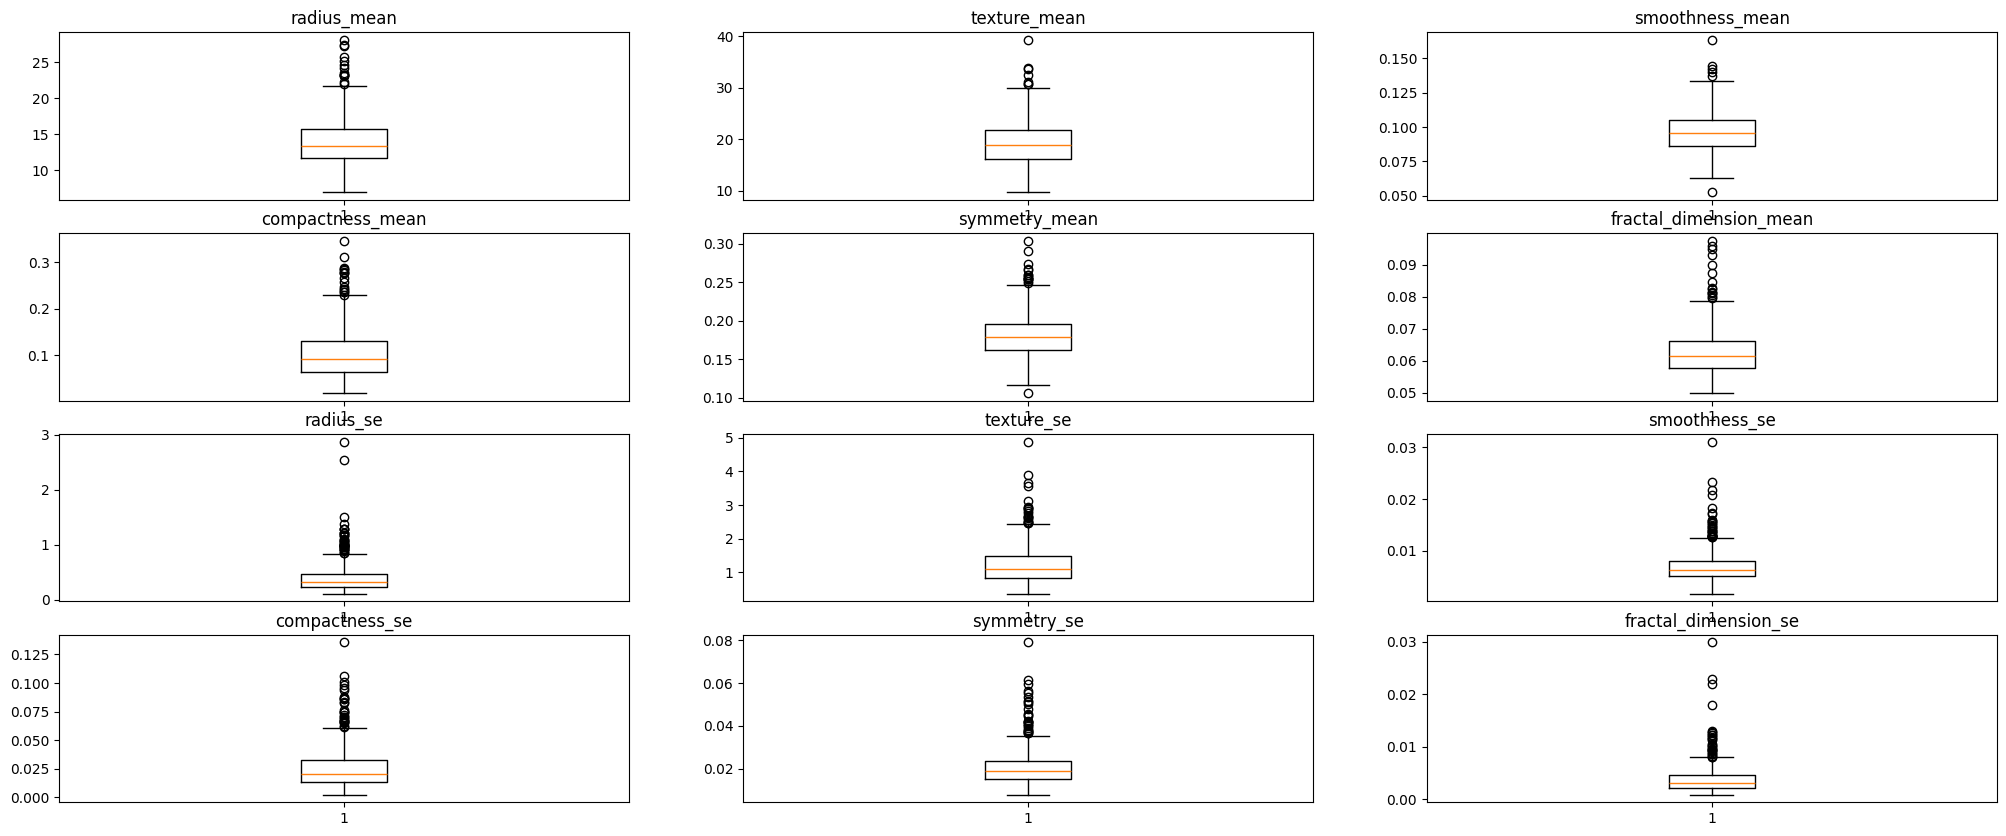

In [58]:
scale_cols_df=pd.DataFrame()
fig, axes = plt.subplots(4,3, figsize=(25,10))
axes = axes.ravel()


for col, ax in zip(new_data_df[num_cols], axes):

  ax.boxplot(new_data_df[col])
  ax.set(title = f'{col}')

  #COMPLETA EL IF
  if not (new_data_df[col].min() >= 0 and new_data_df[col].max() <= 1): scale_cols_df[col] = new_data_df[col]

scale_cols = scale_cols_df.columns.values



In [59]:
scale_cols

array(['radius_mean', 'texture_mean', 'radius_se', 'texture_se'],
      dtype=object)

Con todo el análisis anterior, estamos listos para generar un modelo *baseline* denominado `logr_model`. Para ello:

5a) Vuelve a leer el contenido del archivo, haz que el `id` sea el índice y separa las variables del dataframe: en `X` coloca los predictores y en `y` la variable de respuesta o salida (`diagnosis`). Divide el conjunto en entrenamiento y prueba (80:20) considerando el parámetro `random_state` con el valor de 1.

In [60]:
data_df = pd.read_csv('data.csv')

#AGREGA LINEA DE CODIGO PARA CONVERTIR COLUMNA "ID" EN INDICE

data_df.set_index('id', inplace=True)


In [61]:
X = data_df.copy() #Se crea copia del df

# COMPLETA CODIGO
# se elimina variable Categorica "diagnosis" de (X), debido a se sera utilizada como variable de salida (y)
#Especifique la columna que desea eliminar
#Utilice el parametro axis=1, permitira eliminar la columna
#Guarde los cambios agregando el parametro inplace=True

X.drop('diagnosis', axis=1, inplace=True) #x = indica los predictores

y = data_df['diagnosis'] # y = indica lo que queremos predecir

In [62]:
#Libreria necesaria para realizar la particion del conjunto de datos
# Se divide el conjunto en entrenamiento y prueba (80:20), es decir, 80% para Entrenamiento (train) y 20% para Prueba (test)

from sklearn.model_selection import train_test_split

Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, test_size=0.2, random_state=1)

5b) Prepara un transformador, denominado `preprocessing`, para borrar las columnas altamente correlacionadas (las 18 variables que se determinaron en los ejercicios previos) Asegúrate de incluir el parámetro `remainder='passthrough'` para mantener el resto de las variables.

In [63]:
#EXPLIQUE CADA LINEA DE CODIGO
columnas_a_eliminar=['radius_worst','texture_worst','perimeter_worst','area_worst','smoothness_worst','compactness_worst','concavity_worst','concave points_worst','symmetry_worst','fractal_dimension_worst','perimeter_mean','area_mean','concavity_mean','concave points_mean','perimeter_se','area_se','concavity_se','concave points_se']

preprocessing = ColumnTransformer([
    ('num', 'drop', columnas_a_eliminar)]
   ,remainder='passthrough')


5c) Entrena el modelo `logr_model` con el transformador `preprocessing` y  regresión logística.

Como la salida `y` está en términos de las etiquetas `'B'` y `'M'`, en lugar de 0 y 1, para evaluar el modelo en el conjunto de prueba deberás especificar la clase positiva. En el caso de la matriz de confusión, indica el orden de las etiquetas con `labels=['B','M']`, porque `'B'` es la clase negativa (ésta se especifica primero) y `'M'` la positiva. Para las métricas de *recall* y *precision*, utiliza el parámetro `pos_label='M'`. Como *accuracy* ocupa la suma de ambas clases y el total de las observaciones, no requiere ninguna especificación. Si quisieras omitir estos parámetros, tendrías que sustituir `'B'` por 0 y `'M'` por 1, previo a la construcción del modelo.

In [64]:
#EXPLIQUE CADA LINEA DE CODIGO

logr_model=make_pipeline(preprocessing, LogisticRegression()) #primero borra columnas, luego la regresión logística
logr_model.fit(Xtrain,ytrain) #entrena con el 80% de entrenamiento
predictions=logr_model.predict(Xtest) #predice B o M para el 20% de prueba


print('matriz de confusion 1:\n',confusion_matrix(ytest,predictions,labels=['B','M'])) #labels pone B (negativa) primero y M (positiva) después
print('recall    :\t',recall_score(ytest,predictions,pos_label='M')) #de los malignos reales, cuántos detectó
print('precision :\t',precision_score(ytest,predictions,pos_label='M'))#de los que dijo malignos, cuántos lo eran
print('accurancy :\t',accuracy_score(ytest,predictions)) #aciertos / total


matriz de confusion 1:
 [[68  4]
 [10 32]]
recall    :	 0.7619047619047619
precision :	 0.8888888888888888
accurancy :	 0.8771929824561403


<font color=" ORANGE">INTERPRETE LOS RESULTADOS OBTENIDOS EN MATRIZ DE CONFUSION Y METRICAS

Para generar un modelo `logr_model2` con transformación y escalamiento:

6a) Modifica el transformador anterior para, además del borrado de las columnas correlacionadas, aplicar la raíz cuadrada a los predictores con sesgo (previamente almacenados en `skew_cols`) y escalamiento *MinMax* a los predictores con escala mayor a 1 (previamente almacenados en `scale_cols`) Como no todos los predictores serán eliminados o transformados, asegúrate de incluir el parámetro `remainder='passthrough'`

La matriz muestra 68 verdaderos negativos, 4 falsos positivos, 10 falsos negativos y 32 verdaderos positivos. De 114 casos de prueba acertó 100.

* **Accuracy = 87.7 %**: supera el 70 %, pero hay más benignos (63 %) que malignos (37 %), así que sola no basta.
* **Precision = 88.9 %**: cuando dice "maligno" acierta en 32 de 36 casos.
* **Recall = 76.2 %**: de 42 tumores malignos solo detecta 32. Los 10 falsos negativos son el error más grave, porque son pacientes enfermos que quedarían sin atención.

**¿Qué pasa si no escalamos las variables?** Entran con magnitudes muy distintas (radius_mean ≈ 14 frente a smoothness_mean ≈ 0.1). El algoritmo converge peor y los coeficientes quedan desbalanceados. Además, al borrar 18 variables se pierde información útil (concave points, perimeter, area), y eso explica el recall bajo.

In [65]:
#EXPLIQUE CADA LINEA DE CODIGO
preprocessing2 = ColumnTransformer([                      #tres pasos, cada uno aplicado a sus columnas
    ('num0','drop', columnas_a_eliminar),                 #borra las 18 columnas correlacionadas
    ('num1',FunctionTransformer(np.sqrt),skew_cols),      #raíz cuadrada a las variables con sesgo positivo
    ('num2',MinMaxScaler(),scale_cols)                    #escala a [0,1] las variables cuyo rango es mayor a 1
  ],remainder='passthrough')                              #lo no mencionado pasa sin cambios

6b) Entrena el modelo `logr_model2` con regresión logística, aplicando previamente el transformador modificado. Evalúa el modelo en el conjunto de prueba con las mismas métricas.

In [67]:
logr_model2=make_pipeline(preprocessing2, LogisticRegression())
logr_model2.fit(Xtrain,ytrain)
predictions2=logr_model2.predict(Xtest)

print('matriz de confusion 2:\n',confusion_matrix(ytest,predictions2,labels=['B','M']))
print('recall    :\t',recall_score(ytest,predictions2,pos_label='M'))
print('precision :\t',precision_score(ytest,predictions2,pos_label='M'))
print('accurancy :\t',accuracy_score(ytest,predictions2))

matriz de confusion 2:
 [[72  0]
 [11 31]]
recall    :	 0.7380952380952381
precision :	 1.0
accurancy :	 0.9035087719298246


<font color=" ORANGE">INTERPRETE LOS RESULTADOS OBTENIDOS EN MATRIZ DE CONFUSION Y METRICAS

In [68]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

#borran las columnas _worst
columnas_worst = [c for c in Xtrain.columns if c.endswith('_worst')]

#conjunto de entrenamiento se detectan las variables sesgadas
Xtr_red = Xtrain.drop(columns=columnas_worst)
skew_cols3  = [c for c in Xtr_red.columns if Xtr_red[c].skew() > 1]
resto_cols3 = [c for c in Xtr_red.columns if c not in skew_cols3]

preprocessing3 = ColumnTransformer([
    ('drop_worst', 'drop', columnas_worst),
    ('skew', Pipeline([('raiz', FunctionTransformer(np.sqrt)),
                       ('minmax', MinMaxScaler())]), skew_cols3),
    ('resto', MinMaxScaler(), resto_cols3)
])

#regresión logística balanceada + búsqueda del mejor C con validación cruzada de 5 folds
pipe3 = Pipeline([('preprocessing', preprocessing3),
                  ('logreg', LogisticRegression(class_weight='balanced', max_iter=5000))])

logr_model3 = GridSearchCV(pipe3, param_grid={'logreg__C': [0.1, 1, 10, 100, 1000]},
                           cv=5, scoring='accuracy')
logr_model3.fit(Xtrain, ytrain)
print('Mejor C (validacion cruzada con train):', logr_model3.best_params_)

predictions3 = logr_model3.predict(Xtest)

print('matriz de confusion 3:\n', confusion_matrix(ytest, predictions3, labels=['B','M']))
print('recall    :\t', recall_score(ytest, predictions3, pos_label='M'))
print('precision :\t', precision_score(ytest, predictions3, pos_label='M'))
print('accurancy :\t', accuracy_score(ytest, predictions3))

Mejor C (validacion cruzada con train): {'logreg__C': 100}
matriz de confusion 3:
 [[71  1]
 [ 2 40]]
recall    :	 0.9523809523809523
precision :	 0.975609756097561
accurancy :	 0.9736842105263158


In [69]:
y_bin = (ytest == 'M').astype(int)#m = 1, b = 0

def resumen(modelo, nombre):
    pred  = modelo.predict(Xtest)
    proba = modelo.predict_proba(Xtest)[:, list(modelo.classes_).index('M')]   #probabilidad de ser maligno
    return {'Modelo': nombre,
            'Accuracy': accuracy_score(ytest, pred),
            'Recall (m)': recall_score(ytest, pred, pos_label='M'),
            'Precision (m)': precision_score(ytest, pred, pos_label='M'),
            'R2 (probabilidad)': r2_score(y_bin, proba),
            'R2 (clase 0-1)': r2_score(y_bin, (pred == 'M').astype(int))}

tabla = pd.DataFrame([resumen(logr_model,  'logr_model  (base)'),
                      resumen(logr_model2, 'logr_model2 (raiz + MinMax)'),
                      resumen(logr_model3, 'logr_model3 (mejorado)')]).set_index('Modelo')
tabla.round(3)

,Accuracy,Recall (M),Precision (M),R2 (probabilidad),R2 (clase 0/1)
Modelo,,,,,
logr_model (base),0.877,0.762,0.889,0.577,0.472
logr_model2 (raiz + MinMax),0.904,0.738,1.000,0.610,0.585
logr_model3 (mejorado),0.974,0.952,0.976,0.884,0.887


<font color=" ORANGE">CONCLUSION DE LA PRACTICA

Se construyó un clasificador de regresión logística para diagnosticar tumores de mama como benignos o malignos .

El preprocesamiento es tan importante como el modelo.

En diagnóstico médico el recall es la métrica crítica, porque un falso negativo es el error más costoso.

Borrar variables correlacionadas no siempre mejora el modelo, y con regularización y escalamiento conviene conservar información útil.